# Лабораторная работа №1. Логистическая регрессия
## Предсказание оттока клиентов банка

**Цель:** по характеристикам клиента оценить вероятность ухода из банка и
получить прогноз класса: `Exited = 1` — клиент ушёл, `Exited = 0` — остался.

В работе выполнены загрузка и проверка данных, разведывательный анализ,
подготовка признаков, обучение логистической регрессии, оценка качества,
подбор порога и интерпретация результатов.

### Материалы и источник данных

Постановка взята из приложенного файла `01-Logistic_Regression-ЛР.pdf`.
Архив `Пример-Классификация_Доходов_Людей-(Данные).zip` содержит `adult.csv`:
это данные учебного примера о доходах, а не данные клиентов банка.
Приложенные ноутбуки о диабете и пингвинах иллюстрируют методы классификации.
Дерево решений в постановке необязательно и здесь не используется.

Архив с банковскими данными, указанный в задании, среди приложений отсутствует.
Поэтому использована общедоступная копия **Churn_Modelling.csv** из
[репозитория selva86/datasets](https://github.com/selva86/datasets/blob/master/Churn_Modelling.csv),
загруженная 20.10.2026. Её структура соответствует описанию в задании;
побайтовое совпадение с отсутствующим архивом преподавателя проверить нельзя.
Локальная копия находится в `data/Churn_Modelling.csv`; интернет для запуска не нужен.
В методичке столбец назван `NumOfProduct`, в этой копии — `NumOfProducts`.

**Как запускать:** открыть этот ноутбук в Jupyter и выполнить все ячейки сверху вниз.
Папка `data` должна находиться рядом с ноутбуком. В Google Colab можно загрузить
CSV непосредственно в рабочую папку: код поддерживает и этот путь.
Результаты расчётов и графики сохраняются в папке `results`.


## 1. Импорт библиотек и настройки

Используются NumPy, pandas, matplotlib и scikit-learn. Случайное разбиение
фиксируется параметром `random_state=42`, чтобы результат можно было повторить.


In [1]:
"""Исследование оттока клиентов банка с помощью логистической регрессии."""

import hashlib
import json
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

%matplotlib inline

RANDOM_STATE = 42
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.family": "DejaVu Sans",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 12,
    }
)
pd.set_option("display.max_columns", 20)

versions = {
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "scikit-learn": sklearn.__version__,
}
display(pd.Series(versions, name="Версия"))

Matplotlib is building the font cache; this may take a moment.


numpy            2.4.0
pandas           2.3.3
matplotlib      3.11.2
scikit-learn     1.8.0
Name: Версия, dtype: object

## 2. Загрузка и проверка данных

`RowNumber`, `CustomerId` и `Surname` служат для идентификации и исключаются
из признаков модели. `Exited` — правильный ответ, его нельзя подавать модели
как входной признак. Остальные 10 столбцов описывают клиента:

| Столбец | Содержание |
|---|---|
| CreditScore | Кредитный рейтинг |
| Geography, Gender | Страна проживания и пол |
| Age, Tenure | Возраст и число лет обслуживания |
| Balance | Баланс счетов |
| NumOfProducts | Число банковских продуктов |
| HasCrCard, IsActiveMember | Кредитная карта и активность: 0 или 1 |
| EstimatedSalary | Оценка заработной платы |


In [2]:
data_candidates = [
    Path("data/Churn_Modelling.csv"),
    Path("Churn_Modelling.csv"),
    Path("ЛР_1 /data/Churn_Modelling.csv"),
]
DATA_PATH = next((path for path in data_candidates if path.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Поместите Churn_Modelling.csv в папку data рядом с ноутбуком "
        "или в текущую рабочую папку."
    )

ROOT = DATA_PATH.parent.parent if DATA_PATH.parent.name == "data" else Path.cwd()
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

raw_data = pd.read_csv(DATA_PATH)
data = raw_data.rename(columns={"NumOfProduct": "NumOfProducts"})
data_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print(f"Размер таблицы: {data.shape[0]} строк, {data.shape[1]} столбцов")
print(f"SHA-256: {data_sha256}")
display(data.head())

Размер таблицы: 10000 строк, 14 столбцов
SHA-256: 3996cd1fa372e0db0cd9c0ebac35bbd4e8e3c65fb942bb010c826e7b1eeef0a0


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
numeric_columns = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary",
]
categorical_columns = ["Geography", "Gender"]
binary_columns = ["HasCrCard", "IsActiveMember"]
identifier_columns = ["RowNumber", "CustomerId", "Surname"]
feature_columns = numeric_columns + categorical_columns + binary_columns
required_columns = set(feature_columns + identifier_columns + ["Exited"])
missing_columns = required_columns - set(data.columns)
if missing_columns:
    raise ValueError(f"Отсутствуют столбцы: {sorted(missing_columns)}")

data.info()
display(
    pd.DataFrame(
        {
            "Тип": data.dtypes.astype(str),
            "Пропуски": data.isna().sum(),
            "Уникальные значения": data.nunique(),
        }
    )
)
print("Полных дубликатов:", data.duplicated().sum())
print("Повторяющихся CustomerId:", data["CustomerId"].duplicated().sum())
display(data.describe().round(2))

assert not data.isna().any().any(), "Найдены пропуски: нужна их обработка."
assert not data.duplicated().any(), "Найдены дубли: проверьте их до разбиения."
assert data["CustomerId"].is_unique, "Один клиент встречается несколько раз."
assert set(data["Exited"].unique()) == {0, 1}
assert data[binary_columns].isin([0, 1]).all().all()
assert np.isfinite(data[numeric_columns].to_numpy()).all()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


,Тип,Пропуски,Уникальные значения
RowNumber,int64,0,10000
CustomerId,int64,0,10000
Surname,object,0,2932
CreditScore,int64,0,460
Geography,object,0,3
Gender,object,0,2
Age,int64,0,70
Tenure,int64,0,11
Balance,float64,0,6382
NumOfProducts,int64,0,4


Полных дубликатов: 0
Повторяющихся CustomerId: 0


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.0
mean,5000.50,15690940.57,650.53,38.92,5.01,76485.89,1.53,0.71,0.52,100090.24,0.2
std,2886.90,71936.19,96.65,10.49,2.89,62397.41,0.58,0.46,0.50,57510.49,0.4
min,1.00,15565701.00,350.00,18.00,0.00,0.00,1.00,0.00,0.00,11.58,0.0
25%,2500.75,15628528.25,584.00,32.00,3.00,0.00,1.00,0.00,0.00,51002.11,0.0
50%,5000.50,15690738.00,652.00,37.00,5.00,97198.54,1.00,1.00,1.00,100193.92,0.0
75%,7500.25,15753233.75,718.00,44.00,7.00,127644.24,2.00,1.00,1.00,149388.25,0.0
max,10000.00,15815690.00,850.00,92.00,10.00,250898.09,4.00,1.00,1.00,199992.48,1.0


В используемой копии 10 000 строк и 14 столбцов; пропусков, полных дубликатов
и повторных идентификаторов клиентов нет. Заполнять или удалять строки
не требуется. Нулевой баланс допустим и не считается пропуском. Высокий
возраст сам по себе не является основанием удалять клиента как выброс.

Следующие проверки остановят выполнение, если при замене CSV обнаружатся
пропуски или дубликаты: тогда предобработку нужно пересмотреть.


## 3. Разделение выборки

Выделяем **60%** данных для обучения, **20%** для валидации и **20%** для теста.
`stratify` сохраняет примерно одинаковую долю ушедших клиентов в каждой части.
Разведывательные графики строим по обучающей части. Параметры масштабирования
и кодирования обучаются только на ней; валидация нужна для подбора порога.
Тест используется только для итогового сравнения уже зафиксированных вариантов.


In [4]:
X = data[feature_columns].copy()
y = data["Exited"].copy()
X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_development,
    y_development,
    test_size=0.25,
    stratify=y_development,
    random_state=RANDOM_STATE,
)
assert set(X_train.index).isdisjoint(X_validation.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_validation.index).isdisjoint(X_test.index)
split_summary = pd.DataFrame(
    [
        {"Выборка": name, "Клиентов": len(target), "Доля ушедших": target.mean()}
        for name, target in [
            ("Обучение", y_train),
            ("Валидация", y_validation),
            ("Тест", y_test),
        ]
    ]
).set_index("Выборка")
display(split_summary.round(4))
train_data = data.loc[X_train.index].copy()

,Клиентов,Доля ушедших
Выборка,,
Обучение,6000,0.2038
Валидация,2000,0.2035
Тест,2000,0.2035


## 4. Краткий разведывательный анализ

Проверим баланс классов, распределение возраста и долю ухода по странам и
активности. Эти графики описывают связи в обучающих данных и не доказывают
причин ухода. Размер групп важен: высокая доля в маленькой группе менее надёжна.


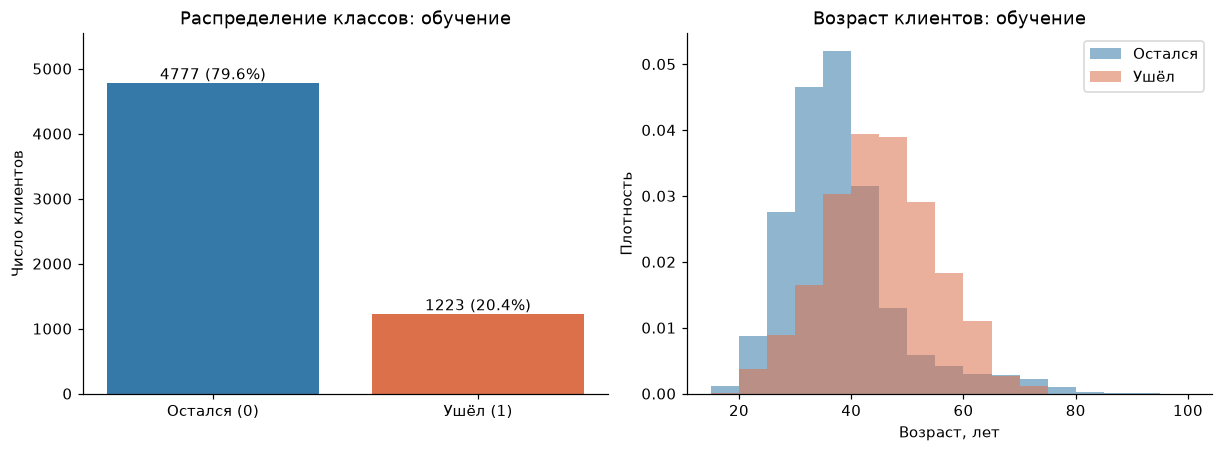

,Доля ухода,Клиентов
Geography,,
France,0.1634,2980
Germany,0.3251,1504
Spain,0.1629,1516


,Доля ухода,Клиентов
IsActiveMember,,
0,0.2700,2907
1,0.1416,3093


,Доля ухода,Клиентов
NumOfProducts,,
1,0.2786,3037
2,0.0731,2762
3,0.8395,162
4,1.0000,39


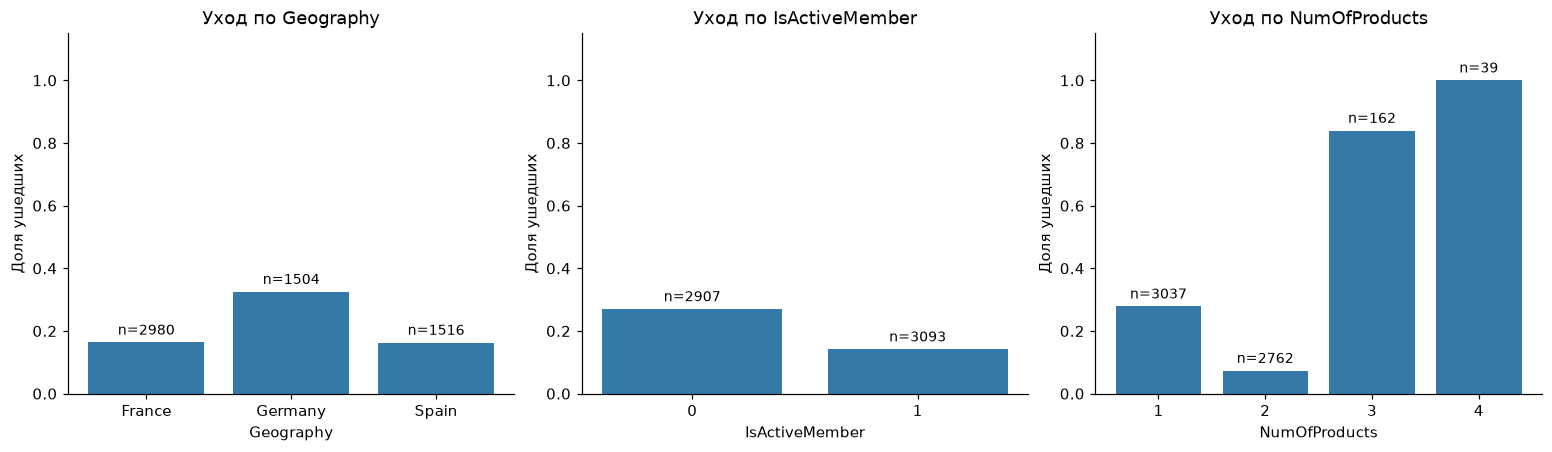

In [5]:
def save_figure(figure, filename):
    """Сохранить график в папку результатов и показать его в ноутбуке."""
    figure.savefig(RESULTS_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(figure)


counts = y_train.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].bar(["Остался (0)", "Ушёл (1)"], counts, color=["#3579a8", "#db704b"])
for index, value in enumerate(counts):
    axes[0].text(
        index, value + 60, f"{value} ({value / len(y_train):.1%})", ha="center"
    )
axes[0].set_ylim(0, counts.max() * 1.16)
axes[0].set_title("Распределение классов: обучение")
axes[0].set_ylabel("Число клиентов")
for label, name, color in [(0, "Остался", "#3579a8"), (1, "Ушёл", "#db704b")]:
    axes[1].hist(
        train_data.loc[train_data["Exited"] == label, "Age"],
        bins=np.arange(15, 101, 5),
        density=True,
        alpha=0.55,
        label=name,
        color=color,
    )
axes[1].set(
    title="Возраст клиентов: обучение", xlabel="Возраст, лет", ylabel="Плотность"
)
axes[1].legend()
save_figure(fig, "01_classes_age.png")

fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for ax, column in zip(
    axes, ["Geography", "IsActiveMember", "NumOfProducts"], strict=True
):
    groups = train_data.groupby(column)["Exited"].agg(["mean", "size"])
    display(groups.rename(columns={"mean": "Доля ухода", "size": "Клиентов"}).round(4))
    ax.bar(groups.index.astype(str), groups["mean"], color="#3579a8")
    for index, row in enumerate(groups.itertuples()):
        ax.text(index, row.mean + 0.025, f"n={row.size}", ha="center", fontsize=9)
    ax.set(
        title=f"Уход по {column}", xlabel=column, ylabel="Доля ушедших", ylim=(0, 1.15)
    )
save_figure(fig, "02_group_churn.png")

Классы несбалансированы: большинство клиентов осталось. Поэтому `accuracy`
обязательно дополняем метриками класса 1. Распределения возраста перекрываются,
и ни один из показанных признаков не разделяет клиентов без ошибок.

У числа продуктов может быть нелинейная связь с уходом: простая линейная модель
с одним коэффициентом `NumOfProducts` не обязана хорошо описывать такую связь.
В рамках задания сохраняем простейшую модель; это ограничение учтём в выводе.


## 5. Подготовка признаков и обучение моделей

Логистическая регрессия вычисляет линейную комбинацию признаков и пропускает
её через сигмоиду:

$$z = b + w_1 x_1 + ldots + w_m x_m,\qquad
P(Exited=1\mid X) = \frac{1}{1 + e^{-z}}.$$

Затем сравниваем вероятность с порогом $t$: прогноз равен 1 при $p\ge t$.
Название содержит слово «регрессия», но здесь модель решает классификацию.

Числовые столбцы стандартизируем: вычитаем среднее и делим на стандартное
отклонение, вычисленные по обучению. Строковые `Geography` и `Gender` кодируем
отдельными бинарными столбцами через `OneHotEncoder`. `drop='first'` оставляет
одну категорию базовой, а `handle_unknown='ignore'` позволяет обрабатывать
новые категории. Бинарные признаки оставляем как 0 и 1.

`Pipeline` связывает обработку и классификатор, чтобы все новые данные
преобразовывались одинаково и тест не влиял на обучение.

Сравниваем три варианта: константный прогноз большинства; логистическую
регрессию на `Age` и `Balance` для наглядной двумерной границы; логистическую
регрессию на всех 10 содержательных признаках. Для обеих регрессий используем
стандартную L2-регуляризацию с `C=1` и до 2000 итераций оптимизации.


In [6]:
two_feature_columns = ["Age", "Balance"]
model_two_features = Pipeline(
    [
        ("preprocessor", StandardScaler()),
        (
            "classifier",
            LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_STATE),
        ),
    ]
)
preprocessor = ColumnTransformer(
    [
        ("numeric", StandardScaler(), numeric_columns),
        (
            "categorical",
            OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
            categorical_columns,
        ),
        ("binary", "passthrough", binary_columns),
    ],
    verbose_feature_names_out=False,
)
model_full = Pipeline(
    [
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_STATE),
        ),
    ]
)
model_dummy = DummyClassifier(strategy="most_frequent")

model_dummy.fit(X_train, y_train)
model_two_features.fit(X_train[two_feature_columns], y_train)
model_full.fit(X_train, y_train)

for name, model in [("Два признака", model_two_features), ("Все признаки", model_full)]:
    print(name, "- итераций:", model.named_steps["classifier"].n_iter_[0])
    assert model.named_steps["classifier"].n_iter_[0] < 2000
print("Признаки после обработки:")
print(model_full.named_steps["preprocessor"].get_feature_names_out().tolist())

Два признака - итераций: 6
Все признаки - итераций: 14
Признаки после обработки:
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male', 'HasCrCard', 'IsActiveMember']


## 6. Метрики и выбор порога на валидации

Положительный класс во всех метриках — ушедший клиент (`Exited=1`).

- **Accuracy:** доля всех верных ответов. При дисбалансе может вводить в заблуждение.
- **Precision:** какая доля отмеченных моделью клиентов действительно ушла.
- **Recall:** какую долю всех ушедших клиентов нашла модель.
- **F1:** гармоническое среднее precision и recall; учитывает обе метрики.
- **ROC-AUC:** качество ранжирования вероятностей по всем порогам.
- **Average precision (AP):** сводная оценка кривой precision-recall.

Для кампании удержания важен recall, но слишком много ложных срабатываний
увеличивает число лишних обращений. Стоимости ошибок и бюджет в задании
не заданы, поэтому заранее выбираем **максимум F1 на валидации** как учебный
компромисс. Это не означает, что такой порог оптимален для прибыли банка.


In [7]:
def evaluate_probabilities(y_true, probabilities, threshold=0.5):
    """Рассчитать метрики бинарной классификации для заданного порога."""
    predictions = (np.asarray(probabilities) >= threshold).astype(int)
    return {
        "threshold": float(threshold),
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "average_precision": average_precision_score(y_true, probabilities),
    }


validation_probabilities = model_full.predict_proba(X_validation)[:, 1]
validation_rows = {
    "Прогноз большинства": evaluate_probabilities(
        y_validation, model_dummy.predict_proba(X_validation)[:, 1]
    ),
    "ЛР: Age, Balance": evaluate_probabilities(
        y_validation,
        model_two_features.predict_proba(X_validation[two_feature_columns])[:, 1],
    ),
    "ЛР: все признаки": evaluate_probabilities(y_validation, validation_probabilities),
}
display(pd.DataFrame(validation_rows).T.round(4))

thresholds = np.arange(5, 96) / 100
threshold_results = pd.DataFrame(
    [
        evaluate_probabilities(y_validation, validation_probabilities, threshold)
        for threshold in thresholds
    ]
)
best_validation_row = threshold_results.sort_values(
    ["f1", "recall", "threshold"], ascending=[False, False, True]
).iloc[0]
best_threshold = float(best_validation_row["threshold"])
print(f"Выбранный по валидации порог: {best_threshold:.2f}")
display(best_validation_row.to_frame("Метрики валидации").round(4))
threshold_results.to_csv(RESULTS_DIR / "validation_thresholds.csv", index=False)

,threshold,accuracy,precision,recall,f1,roc_auc,average_precision
Прогноз большинства,0.5,0.7965,0.0000,0.0000,0.0000,0.5000,0.2035
"ЛР: Age, Balance",0.5,0.7815,0.3171,0.0639,0.1063,0.7247,0.3611
ЛР: все признаки,0.5,0.8090,0.5839,0.2138,0.3129,0.7567,0.4631


Выбранный по валидации порог: 0.20


,Метрики валидации
threshold,0.2000
accuracy,0.7005
precision,0.3717
recall,0.6830
f1,0.4814
roc_auc,0.7567
average_precision,0.4631


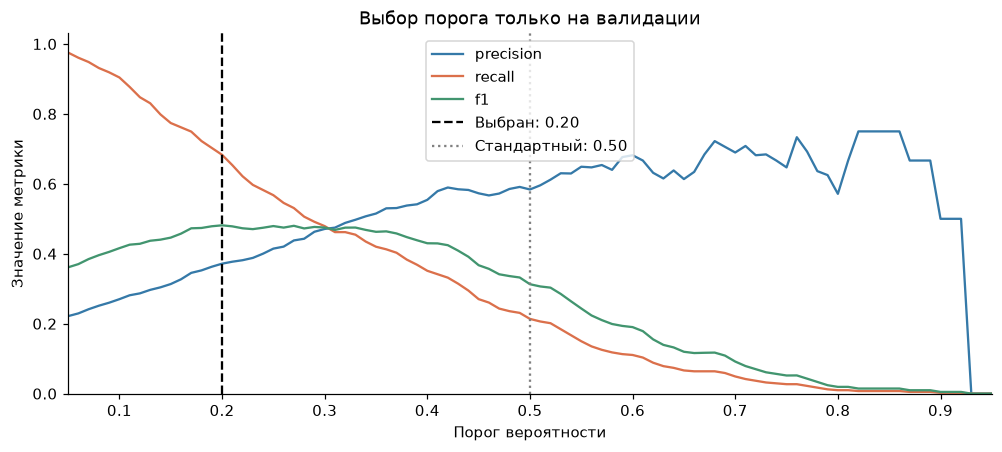

In [8]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
for metric, color in [
    ("precision", "#3579a8"),
    ("recall", "#db704b"),
    ("f1", "#42956f"),
]:
    ax.plot(
        threshold_results["threshold"],
        threshold_results[metric],
        label=metric,
        color=color,
    )
ax.axvline(
    best_threshold, color="black", linestyle="--", label=f"Выбран: {best_threshold:.2f}"
)
ax.axvline(0.5, color="gray", linestyle=":", label="Стандартный: 0.50")
ax.set(
    title="Выбор порога только на валидации",
    xlabel="Порог вероятности",
    ylabel="Значение метрики",
    xlim=(0.05, 0.95),
    ylim=(0, 1.03),
)
ax.legend()
save_figure(fig, "03_validation_thresholds.png")

Порог зафиксирован до обращения к тестовым ответам. При равном F1 выбирается
вариант с большим recall, затем с меньшим порогом. После выбора порога
модель не переобучаем: иначе распределение её вероятностей могло бы измениться.

Снижение порога увеличивает число клиентов, которым предсказывается уход.
Recall при этом не уменьшается, а precision может колебаться; его рост при
увеличении порога не гарантирован для каждого шага на конечной выборке.


## 7. Итоговая оценка на тестовой выборке

Теперь сравним заранее определённые варианты на клиентах, не использованных
ни при обучении, ни при выборе порога. У полной модели меняется только порог:
её коэффициенты и вероятности остаются прежними.


In [9]:
test_probabilities_dummy = model_dummy.predict_proba(X_test)[:, 1]
test_probabilities_two = model_two_features.predict_proba(X_test[two_feature_columns])[
    :, 1
]
test_probabilities_full = model_full.predict_proba(X_test)[:, 1]
test_predictions_default = (test_probabilities_full >= 0.5).astype(int)
test_predictions_tuned = (test_probabilities_full >= best_threshold).astype(int)

test_rows = {
    "Прогноз большинства": evaluate_probabilities(y_test, test_probabilities_dummy),
    "ЛР: Age, Balance; t=0.50": evaluate_probabilities(y_test, test_probabilities_two),
    "ЛР: все признаки; t=0.50": evaluate_probabilities(y_test, test_probabilities_full),
    f"ЛР: все признаки; t={best_threshold:.2f}": evaluate_probabilities(
        y_test, test_probabilities_full, best_threshold
    ),
}
test_metrics = pd.DataFrame(test_rows).T.rename_axis("model")
display(test_metrics.round(4))
test_metrics.to_csv(RESULTS_DIR / "test_metrics.csv")

print("Отчёт для полной модели со стандартным порогом:")
print(
    classification_report(
        y_test,
        test_predictions_default,
        target_names=["Остался", "Ушёл"],
        digits=4,
        zero_division=0,
    )
)
print(f"Отчёт для полной модели с порогом {best_threshold:.2f}:")
print(
    classification_report(
        y_test,
        test_predictions_tuned,
        target_names=["Остался", "Ушёл"],
        digits=4,
        zero_division=0,
    )
)

,threshold,accuracy,precision,recall,f1,roc_auc,average_precision
model,,,,,,,
Прогноз большинства,0.5,0.7965,0.0000,0.0000,0.0000,0.5000,0.2035
"ЛР: Age, Balance; t=0.50",0.5,0.7835,0.3030,0.0491,0.0846,0.7416,0.3781
ЛР: все признаки; t=0.50,0.5,0.8090,0.5969,0.1892,0.2873,0.7753,0.4806
ЛР: все признаки; t=0.20,0.2,0.7020,0.3777,0.7174,0.4949,0.7753,0.4806


Отчёт для полной модели со стандартным порогом:
              precision    recall  f1-score   support

     Остался     0.8236    0.9674    0.8897      1593
        Ушёл     0.5969    0.1892    0.2873       407

    accuracy                         0.8090      2000
   macro avg     0.7103    0.5783    0.5885      2000
weighted avg     0.7775    0.8090    0.7671      2000

Отчёт для полной модели с порогом 0.20:
              precision    recall  f1-score   support

     Остался     0.9063    0.6981    0.7887      1593
        Ушёл     0.3777    0.7174    0.4949       407

    accuracy                         0.7020      2000
   macro avg     0.6420    0.7077    0.6418      2000
weighted avg     0.7987    0.7020    0.7289      2000



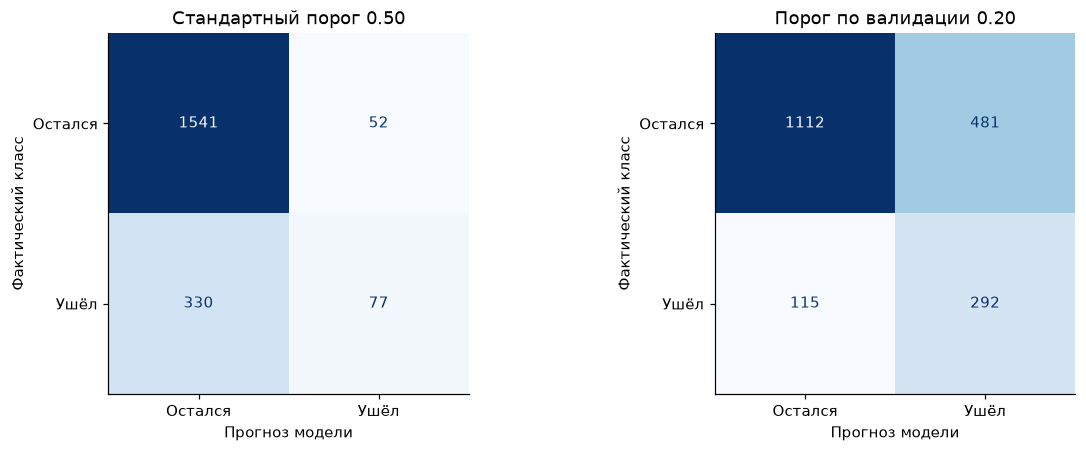

На тесте **407** ушедших клиентов. При пороге 0.50 модель нашла **77** и пропустила **330**; ложных тревог — **52**. При пороге 0.20 нашла **292**, пропустила **115**, ложных тревог — **481**.

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, prediction, title in [
    (axes[0], test_predictions_default, "Стандартный порог 0.50"),
    (axes[1], test_predictions_tuned, f"Порог по валидации {best_threshold:.2f}"),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        prediction,
        display_labels=["Остался", "Ушёл"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set(title=title, xlabel="Прогноз модели", ylabel="Фактический класс")
save_figure(fig, "04_confusion_matrices.png")

tn_default, fp_default, fn_default, tp_default = confusion_matrix(
    y_test, test_predictions_default
).ravel()
tn_tuned, fp_tuned, fn_tuned, tp_tuned = confusion_matrix(
    y_test, test_predictions_tuned
).ravel()
display(
    Markdown(
        f"На тесте **{int(y_test.sum())}** ушедших клиентов. "
        f"При пороге 0.50 модель нашла **{tp_default}** и пропустила **{fn_default}**; "
        f"ложных тревог — **{fp_default}**. "
        f"При пороге {best_threshold:.2f} нашла **{tp_tuned}**, пропустила **{fn_tuned}**, "
        f"ложных тревог — **{fp_tuned}**."
    )
)

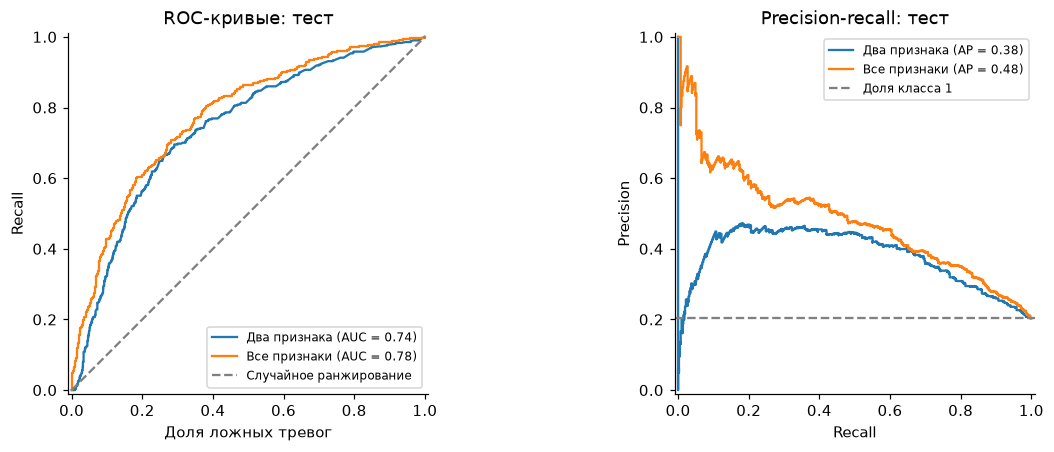

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for name, probabilities in [
    ("Два признака", test_probabilities_two),
    ("Все признаки", test_probabilities_full),
]:
    RocCurveDisplay.from_predictions(y_test, probabilities, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(
        y_test, probabilities, name=name, ax=axes[1]
    )
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Случайное ранжирование")
axes[1].axhline(y_test.mean(), color="gray", linestyle="--", label="Доля класса 1")
axes[0].set(title="ROC-кривые: тест", xlabel="Доля ложных тревог", ylabel="Recall")
axes[1].set(title="Precision-recall: тест", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.legend(fontsize=8)
save_figure(fig, "05_roc_precision_recall.png")

ROC-AUC и AP у полной модели одинаковы для двух порогов, потому что они
вычисляются по одним и тем же вероятностям. Порог меняет итоговые классы,
precision, recall и F1. AP сравниваем с долей положительного класса,
а ROC-AUC — с уровнем 0.5 для случайного ранжирования.


## 8. Визуализация границы решения простой модели

У модели на `Age` и `Balance` можно показать карту вероятностей в двух измерениях.
Чёрная линия соответствует стандартному порогу 0.5. Точки — только обучающие
клиенты. Для полной модели с множеством признаков аналогичный двумерный рисунок
не отображал бы всё пространство признаков.


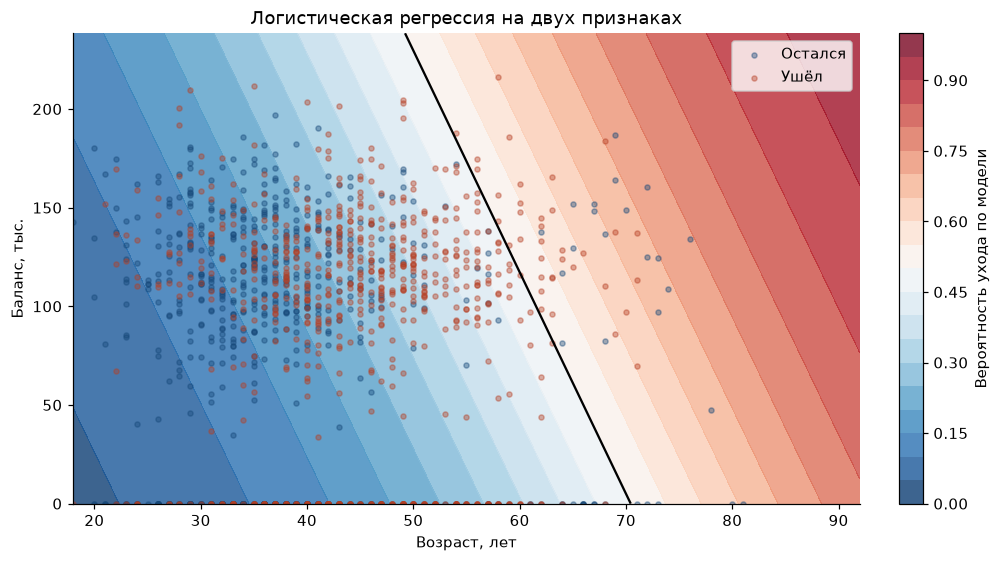

In [12]:
age_grid, balance_grid = np.meshgrid(
    np.linspace(X_train["Age"].min(), X_train["Age"].max(), 180),
    np.linspace(X_train["Balance"].min(), X_train["Balance"].max(), 160),
)
grid = pd.DataFrame({"Age": age_grid.ravel(), "Balance": balance_grid.ravel()})
grid_probabilities = model_two_features.predict_proba(grid)[:, 1].reshape(
    age_grid.shape
)
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
contour = ax.contourf(
    age_grid,
    balance_grid / 1000,
    grid_probabilities,
    levels=np.linspace(0, 1, 21),
    cmap="RdBu_r",
    vmin=0,
    vmax=1,
    alpha=0.8,
)
ax.contour(
    age_grid, balance_grid / 1000, grid_probabilities, levels=[0.5], colors="black"
)
for label, name, color in [(0, "Остался", "#164879"), (1, "Ушёл", "#b63f24")]:
    group = train_data.loc[train_data["Exited"] == label].sample(
        n=min(700, int((y_train == label).sum())), random_state=RANDOM_STATE
    )
    ax.scatter(
        group["Age"], group["Balance"] / 1000, c=color, s=11, alpha=0.4, label=name
    )
fig.colorbar(contour, ax=ax, label="Вероятность ухода по модели")
ax.set(
    title="Логистическая регрессия на двух признаках",
    xlabel="Возраст, лет",
    ylabel="Баланс, тыс.",
)
ax.legend()
save_figure(fig, "06_decision_boundary.png")

## 9. Интерпретация полной модели

Положительный коэффициент увеличивает логарифм отношения шансов ухода,
отрицательный — уменьшает, при фиксированных остальных признаках.
`exp(coef)` — множитель **шансов**, а не вероятности.

Для числовых признаков коэффициент относится к увеличению на одно стандартное
отклонение в обучении; для бинарных — к переходу 0 → 1. Категориальные
коэффициенты сравниваются с базовой категорией, которую выводим ниже.
Такие связи не доказывают причинность и зависят от выбранной модели.


Свободный член: -0.8823
Базовые категории: {'Geography': 'France', 'Gender': 'Female'}


,feature,coefficient,odds_ratio
1,Age,0.7356,2.0867
6,Geography_Germany,0.7213,2.0572
3,Balance,0.2099,1.2336
5,EstimatedSalary,0.0607,1.0626
7,Geography_Spain,-0.0187,0.9815
4,NumOfProducts,-0.0314,0.9691
2,Tenure,-0.0335,0.9671
0,CreditScore,-0.0531,0.9483
9,HasCrCard,-0.1150,0.8914
8,Gender_Male,-0.5664,0.5675


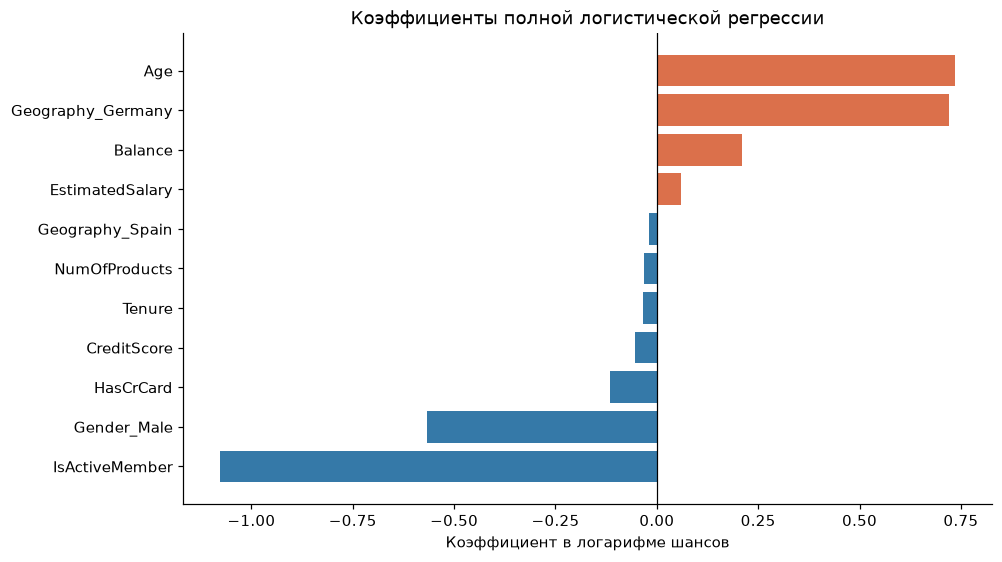

In [13]:
fitted_preprocessor = model_full.named_steps["preprocessor"]
classifier = model_full.named_steps["classifier"]
coefficients = pd.DataFrame(
    {
        "feature": fitted_preprocessor.get_feature_names_out(),
        "coefficient": classifier.coef_[0],
        "odds_ratio": np.exp(classifier.coef_[0]),
    }
).sort_values("coefficient", ascending=False)
print(f"Свободный член: {classifier.intercept_[0]:.4f}")
encoder = fitted_preprocessor.named_transformers_["categorical"]
print(
    "Базовые категории:",
    {
        column: categories[0]
        for column, categories in zip(
            categorical_columns, encoder.categories_, strict=True
        )
    },
)
display(coefficients.round(4))
coefficients.to_csv(RESULTS_DIR / "coefficients.csv", index=False)

ordered_coefficients = coefficients.sort_values("coefficient")
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.barh(
    ordered_coefficients["feature"],
    ordered_coefficients["coefficient"],
    color=np.where(ordered_coefficients["coefficient"] > 0, "#db704b", "#3579a8"),
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(
    title="Коэффициенты полной логистической регрессии",
    xlabel="Коэффициент в логарифме шансов",
)
save_figure(fig, "07_coefficients.png")

В обученной модели положительные коэффициенты имеют возраст, проживание
в Германии относительно Франции и баланс. Статус активного клиента связан
с меньшими шансами ухода. Небольшой коэффициент `NumOfProducts` не доказывает,
что число продуктов не связано с уходом: линейная форма может не отражать
неодинаковый риск для одного, двух, трёх и четырёх продуктов.

Модель включает пол и страну как в исходном учебном наборе. Перед применением
для реальных решений потребовалось бы проверить качество и ошибки по группам.


## 10. Пример прогноза и сохранение результатов

Покажем первые восемь клиентов тестовой части в исходном порядке этой части.
`probability_exit` — оценка вероятности моделью; `prediction_tuned` — её
решение при выбранном по валидации пороге. Это прогноз, а не гарантия ухода.


In [14]:
test_predictions = data.loc[X_test.index, ["RowNumber", "CustomerId", "Exited"]].copy()
test_predictions["probability_exit"] = test_probabilities_full
test_predictions["prediction_050"] = test_predictions_default
test_predictions["prediction_tuned"] = test_predictions_tuned
display(test_predictions.head(8).round(4))
test_predictions.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)

one_client = X_test.iloc[[0]]
one_probability = model_full.predict_proba(one_client)[0, 1]
print(f"Вероятность ухода первого клиента: {one_probability:.2%}")
print(
    f"Прогноз при пороге {best_threshold:.2f}: {int(one_probability >= best_threshold)}"
)

experiment_summary = {
    "random_state": RANDOM_STATE,
    "data_sha256": data_sha256,
    "source_url": "https://github.com/selva86/datasets/blob/master/Churn_Modelling.csv",
    "versions": versions,
    "split_sizes": {
        "train": len(y_train),
        "validation": len(y_validation),
        "test": len(y_test),
    },
    "threshold_selection": "maximum validation F1 on grid 0.05..0.95, step 0.01",
    "selected_threshold": best_threshold,
    "validation_selected_metrics": best_validation_row.to_dict(),
    "test_metrics": test_metrics.reset_index().to_dict(orient="records"),
    "confusion_matrix_default": confusion_matrix(
        y_test, test_predictions_default
    ).tolist(),
    "confusion_matrix_tuned": confusion_matrix(y_test, test_predictions_tuned).tolist(),
}
(RESULTS_DIR / "experiment_summary.json").write_text(
    json.dumps(experiment_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)

,RowNumber,CustomerId,Exited,probability_exit,prediction_050,prediction_tuned
5702,5703,15749540,0,0.1142,0,0
3667,3668,15807340,0,0.2778,0,1
1617,1618,15801062,0,0.1071,0,0
5673,5674,15572801,0,0.1553,0,0
4272,4273,15600708,0,0.0905,0,0
8270,8271,15703544,0,0.1229,0,0
7079,7080,15704081,0,0.0793,0,0
5295,5296,15801788,0,0.3666,0,1


Вероятность ухода первого клиента: 11.42%
Прогноз при пороге 0.20: 0


2115

## 11. Выводы


In [15]:
default_result = test_rows["ЛР: все признаки; t=0.50"]
tuned_result = test_rows[f"ЛР: все признаки; t={best_threshold:.2f}"]
display(
    Markdown(
        f"1. Подготовлен набор из **{len(data):,} клиентов**: удалены из входа идентификаторы, "
        "числовые признаки стандартизированы, категории закодированы. "
        "Обработка обучалась только на тренировочной части.\n"
        f"2. При стандартном пороге полная логистическая регрессия даёт "
        f"**accuracy {default_result['accuracy']:.3f}**, но находит только "
        f"**{default_result['recall']:.1%}** ушедших. Высокой accuracy недостаточно.\n"
        f"3. На валидации выбран порог **{best_threshold:.2f}**. На тесте он даёт "
        f"**recall {tuned_result['recall']:.3f}**, **precision {tuned_result['precision']:.3f}**, "
        f"**F1 {tuned_result['f1']:.3f}**. Обнаружено {tp_tuned} из {int(y_test.sum())} "
        f"ушедших, ложных тревог {fp_tuned}.\n"
        f"4. **ROC-AUC {tuned_result['roc_auc']:.3f}** и "
        f"**AP {tuned_result['average_precision']:.3f}** показывают, что модель "
        "ранжирует риск лучше константного прогноза. Она остаётся простой исходной моделью.\n"
        "5. Для кампании удержания снижение порога позволяет найти больше "
        "уходящих клиентов ценой дополнительных ложных тревог. Выбор рабочего порога "
        "нужно связать со стоимостью контакта, ценностью удержания и бюджетом."
    )
)

1. Подготовлен набор из **10,000 клиентов**: удалены из входа идентификаторы, числовые признаки стандартизированы, категории закодированы. Обработка обучалась только на тренировочной части.
2. При стандартном пороге полная логистическая регрессия даёт **accuracy 0.809**, но находит только **18.9%** ушедших. Высокой accuracy недостаточно.
3. На валидации выбран порог **0.20**. На тесте он даёт **recall 0.717**, **precision 0.378**, **F1 0.495**. Обнаружено 292 из 407 ушедших, ложных тревог 481.
4. **ROC-AUC 0.775** и **AP 0.481** показывают, что модель ранжирует риск лучше константного прогноза. Она остаётся простой исходной моделью.
5. Для кампании удержания снижение порога позволяет найти больше уходящих клиентов ценой дополнительных ложных тревог. Выбор рабочего порога нужно связать со стоимостью контакта, ценностью удержания и бюджетом.

**Ограничения.** Оценка получена на одном случайном разбиении учебного набора.
В данных нет даты ухода, поэтому модель оценивает метку `Exited`, но не
конкретный срок «ближайшего времени». Случайный тест не заменяет проверку
на более поздних клиентах. Вероятности не проверены на калибровку.
Линейная модель может пропускать нелинейности и взаимодействия признаков.
Прогноз риска не доказывает, что конкретная кампания удержит клиента.

**Что можно улучшить далее:** проверить устойчивость метрик на нескольких
разбиениях или кросс-валидации; оценить калибровку; проверить нелинейное
представление числа продуктов и возраста. Это направления дальнейшей работы,
а не выполненные в этой лабораторной эксперименты.

### Использованные материалы

- Приложенные преподавателем задание и методичка по логистической регрессии.
- Приложенные примеры кода: бинарная классификация диабета и классификация пингвинов.
- [Локальная копия исходного банковского набора](data/Churn_Modelling.csv) и
  [страница источника](https://github.com/selva86/datasets/blob/master/Churn_Modelling.csv).
- [Документация LogisticRegression](https://scikit-learn.org/1.8/modules/generated/sklearn.linear_model.LogisticRegression.html).
- [Предотвращение утечки данных](https://scikit-learn.org/1.8/common_pitfalls.html).
- [Подбор порога классификации](https://scikit-learn.org/1.8/modules/classification_threshold.html).
